# FlightIQ — Intelligent Flight Delay & Operational Risk Prediction System

### Machine Learning Capstone Project

**Objective:**  
FlightIQ is a machine learning system designed to predict flight delay risk and estimate the expected delay duration using flight information available before departure.

### Machine Learning Models
- Linear Regression — Delay Duration Prediction
- Logistic Regression — Delay / No-Delay Classification
- Decision Tree — Delay Classification and Model Interpretability

### Project Workflow
1. Problem Definition & Business Understanding
2. Data Understanding
3. Data Cleaning & Preprocessing
4. Exploratory Data Analysis
5. Feature Engineering & Selection
6. Model Development
7. Model Evaluation & Validation
8. Business Insights & Recommendations
9. Deployment

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Dataset & Data Understanding

In this section, we examine the structure, features, data types, and quality of the 2022 flight dataset before performing preprocessing or model development.

In [3]:
DATA_PATH = "data/flight_data_2022.csv"

sample_df = pd.read_csv(DATA_PATH, nrows=5)

print("Dataset preview:")
display(sample_df)

Dataset preview:


,FlightDate,Airline,Origin,Dest,Cancelled,Diverted,CRSDepTime,DepTime,DepDelayMinutes,DepDelay,...,WheelsOff,WheelsOn,TaxiIn,CRSArrTime,ArrDelay,ArrDel15,ArrivalDelayGroups,ArrTimeBlk,DistanceGroup,DivAirportLandings
0,2022-04-04,"Commutair Aka Champlain Enterprises, Inc.",GJT,DEN,False,False,1133,1123.0,0.0,-10.0,...,1140.0,1220.0,8.0,1245,-17.0,0.0,-2.0,1200-1259,1,0
1,2022-04-04,"Commutair Aka Champlain Enterprises, Inc.",HRL,IAH,False,False,732,728.0,0.0,-4.0,...,744.0,839.0,9.0,849,-1.0,0.0,-1.0,0800-0859,2,0
2,2022-04-04,"Commutair Aka Champlain Enterprises, Inc.",DRO,DEN,False,False,1529,1514.0,0.0,-15.0,...,1535.0,1622.0,14.0,1639,-3.0,0.0,-1.0,1600-1659,2,0
3,2022-04-04,"Commutair Aka Champlain Enterprises, Inc.",IAH,GPT,False,False,1435,1430.0,0.0,-5.0,...,1446.0,1543.0,4.0,1605,-18.0,0.0,-2.0,1600-1659,2,0
4,2022-04-04,"Commutair Aka Champlain Enterprises, Inc.",DRO,DEN,False,False,1135,1135.0,0.0,0.0,...,1154.0,1243.0,8.0,1245,6.0,0.0,0.0,1200-1259,2,0


In [4]:
print("Number of columns:", len(sample_df.columns))

print("\nColumn names:")
for i, column in enumerate(sample_df.columns, start=1):
    print(f"{i}. {column}")

Number of columns: 61

Column names:
1. FlightDate
2. Airline
3. Origin
4. Dest
5. Cancelled
6. Diverted
7. CRSDepTime
8. DepTime
9. DepDelayMinutes
10. DepDelay
11. ArrTime
12. ArrDelayMinutes
13. AirTime
14. CRSElapsedTime
15. ActualElapsedTime
16. Distance
17. Year
18. Quarter
19. Month
20. DayofMonth
21. DayOfWeek
22. Marketing_Airline_Network
23. Operated_or_Branded_Code_Share_Partners
24. DOT_ID_Marketing_Airline
25. IATA_Code_Marketing_Airline
26. Flight_Number_Marketing_Airline
27. Operating_Airline
28. DOT_ID_Operating_Airline
29. IATA_Code_Operating_Airline
30. Tail_Number
31. Flight_Number_Operating_Airline
32. OriginAirportID
33. OriginAirportSeqID
34. OriginCityMarketID
35. OriginCityName
36. OriginState
37. OriginStateFips
38. OriginStateName
39. OriginWac
40. DestAirportID
41. DestAirportSeqID
42. DestCityMarketID
43. DestCityName
44. DestState
45. DestStateFips
46. DestStateName
47. DestWac
48. DepDel15
49. DepartureDelayGroups
50. DepTimeBlk
51. TaxiOut
52. WheelsOff
5

In [5]:
for i, column in enumerate(sample_df.columns, start=1):
    print(f"{i:2}. {column}")

 1. FlightDate
 2. Airline
 3. Origin
 4. Dest
 5. Cancelled
 6. Diverted
 7. CRSDepTime
 8. DepTime
 9. DepDelayMinutes
10. DepDelay
11. ArrTime
12. ArrDelayMinutes
13. AirTime
14. CRSElapsedTime
15. ActualElapsedTime
16. Distance
17. Year
18. Quarter
19. Month
20. DayofMonth
21. DayOfWeek
22. Marketing_Airline_Network
23. Operated_or_Branded_Code_Share_Partners
24. DOT_ID_Marketing_Airline
25. IATA_Code_Marketing_Airline
26. Flight_Number_Marketing_Airline
27. Operating_Airline
28. DOT_ID_Operating_Airline
29. IATA_Code_Operating_Airline
30. Tail_Number
31. Flight_Number_Operating_Airline
32. OriginAirportID
33. OriginAirportSeqID
34. OriginCityMarketID
35. OriginCityName
36. OriginState
37. OriginStateFips
38. OriginStateName
39. OriginWac
40. DestAirportID
41. DestAirportSeqID
42. DestCityMarketID
43. DestCityName
44. DestState
45. DestStateFips
46. DestStateName
47. DestWac
48. DepDel15
49. DepartureDelayGroups
50. DepTimeBlk
51. TaxiOut
52. WheelsOff
53. WheelsOn
54. TaxiIn
55. C

In [6]:
print("Number of rows inspected:", len(sample_df))
print("Number of columns:", sample_df.shape[1])

print("\nData types:")
display(sample_df.dtypes)

Number of rows inspected: 5
Number of columns: 61

Data types:


FlightDate             object
Airline                object
Origin                 object
Dest                   object
Cancelled                bool
                       ...   
ArrDel15              float64
ArrivalDelayGroups    float64
ArrTimeBlk             object
DistanceGroup           int64
DivAirportLandings      int64
Length: 61, dtype: object

In [7]:
# Create a complete column inventory
column_info = pd.DataFrame({
    "Column_Number": range(1, len(sample_df.columns) + 1),
    "Column_Name": sample_df.columns,
    "Data_Type": sample_df.dtypes.astype(str).values
})

display(column_info)

,Column_Number,Column_Name,Data_Type
0,1,FlightDate,object
1,2,Airline,object
2,3,Origin,object
3,4,Dest,object
4,5,Cancelled,bool
...,...,...,...
56,57,ArrDel15,float64
57,58,ArrivalDelayGroups,float64
58,59,ArrTimeBlk,object
59,60,DistanceGroup,int64


In [8]:
for i, column in enumerate(sample_df.columns[:20], start=1):
    print(f"{i:2}. {column}")

 1. FlightDate
 2. Airline
 3. Origin
 4. Dest
 5. Cancelled
 6. Diverted
 7. CRSDepTime
 8. DepTime
 9. DepDelayMinutes
10. DepDelay
11. ArrTime
12. ArrDelayMinutes
13. AirTime
14. CRSElapsedTime
15. ActualElapsedTime
16. Distance
17. Year
18. Quarter
19. Month
20. DayofMonth


In [9]:
for i, column in enumerate(sample_df.columns[20:40], start=21):
    print(f"{i:2}. {column}")

21. DayOfWeek
22. Marketing_Airline_Network
23. Operated_or_Branded_Code_Share_Partners
24. DOT_ID_Marketing_Airline
25. IATA_Code_Marketing_Airline
26. Flight_Number_Marketing_Airline
27. Operating_Airline
28. DOT_ID_Operating_Airline
29. IATA_Code_Operating_Airline
30. Tail_Number
31. Flight_Number_Operating_Airline
32. OriginAirportID
33. OriginAirportSeqID
34. OriginCityMarketID
35. OriginCityName
36. OriginState
37. OriginStateFips
38. OriginStateName
39. OriginWac
40. DestAirportID


In [10]:
for i, column in enumerate(sample_df.columns[40:61], start=41):
    print(f"{i:2}. {column}")

41. DestAirportSeqID
42. DestCityMarketID
43. DestCityName
44. DestState
45. DestStateFips
46. DestStateName
47. DestWac
48. DepDel15
49. DepartureDelayGroups
50. DepTimeBlk
51. TaxiOut
52. WheelsOff
53. WheelsOn
54. TaxiIn
55. CRSArrTime
56. ArrDelay
57. ArrDel15
58. ArrivalDelayGroups
59. ArrTimeBlk
60. DistanceGroup
61. DivAirportLandings


In [11]:
print("Sample cancellation status:")
print(sample_df["Cancelled"].value_counts(dropna=False))

print("\nSample diversion status:")
print(sample_df["Diverted"].value_counts(dropna=False))

Sample cancellation status:
Cancelled
False    5
Name: count, dtype: int64

Sample diversion status:
Diverted
False    5
Name: count, dtype: int64


In [12]:
print("Sample arrival delay values:")
display(sample_df[["ArrDelayMinutes", "ArrDel15"]])

Sample arrival delay values:


,ArrDelayMinutes,ArrDel15
0,0.0,0.0
1,0.0,0.0
2,0.0,0.0
3,0.0,0.0
4,6.0,0.0


## 3. Data Preprocessing & Cleaning

The original dataset contains flight-level operational information for flights in 2022.

For FlightIQ, the prediction is made **before the scheduled departure**. Therefore, only information available before departure is used as a model input.

The preprocessing steps include:

1. Selecting relevant columns
2. Removing cancelled and diverted flights
3. Handling missing target values
4. Creating the delay classification target
5. Creating useful time-based features
6. Removing data leakage and unnecessary identifiers
7. Preparing the final modeling dataset

In [13]:
# Columns required for FlightIQ modeling

model_columns = [
    "FlightDate",
    "Airline",
    "Origin",
    "Dest",
    "Cancelled",
    "Diverted",
    "CRSDepTime",
    "CRSArrTime",
    "CRSElapsedTime",
    "Distance",
    "Month",
    "DayofMonth",
    "DayOfWeek",
    "Marketing_Airline_Network",
    "Operating_Airline",
    "OriginAirportID",
    "DestAirportID",
    "DepTimeBlk",
    "ArrTimeBlk",
    "DistanceGroup",
    "ArrDelayMinutes"
]

print("Number of selected columns:", len(model_columns))
print("\nSelected columns:")
for col in model_columns:
    print("-", col)

Number of selected columns: 21

Selected columns:
- FlightDate
- Airline
- Origin
- Dest
- Cancelled
- Diverted
- CRSDepTime
- CRSArrTime
- CRSElapsedTime
- Distance
- Month
- DayofMonth
- DayOfWeek
- Marketing_Airline_Network
- Operating_Airline
- OriginAirportID
- DestAirportID
- DepTimeBlk
- ArrTimeBlk
- DistanceGroup
- ArrDelayMinutes


In [14]:
# Count the total number of rows efficiently

total_rows = 0

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=["FlightDate"],
    chunksize=100_000
):
    total_rows += len(chunk)

print("Total rows in dataset:", total_rows)

Total rows in dataset: 4078318


In [15]:
# Create a manageable modeling dataset from the large CSV

sample_chunks = []

chunk_size = 100_000
sample_per_chunk = 25_000

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=model_columns,
    chunksize=chunk_size
):
    
    # Remove cancelled and diverted flights
    chunk = chunk[
        (chunk["Cancelled"] == False) &
        (chunk["Diverted"] == False)
    ]
    
    # Remove rows where the target is missing
    chunk = chunk.dropna(subset=["ArrDelayMinutes"])
    
    # Take a representative sample from this chunk
    if len(chunk) > sample_per_chunk:
        chunk = chunk.sample(
            n=sample_per_chunk,
            random_state=42
        )
    
    sample_chunks.append(chunk)

# Combine all sampled chunks
model_df = pd.concat(sample_chunks, ignore_index=True)

print("Modeling dataset shape:", model_df.shape)
print("Number of rows:", len(model_df))
print("Number of columns:", len(model_df.columns))

Modeling dataset shape: (1025000, 21)
Number of rows: 1025000
Number of columns: 21


In [16]:
# Create the classification target

model_df["IsDelayed"] = (
    model_df["ArrDelayMinutes"] >= 15
).astype(int)

print("Target column created successfully!")

print("\nDelay class distribution:")
print(model_df["IsDelayed"].value_counts())

print("\nDelay class percentage:")
print(
    (model_df["IsDelayed"].value_counts(normalize=True) * 100)
    .round(2)
)

Target column created successfully!

Delay class distribution:
IsDelayed
0    803328
1    221672
Name: count, dtype: int64

Delay class percentage:
IsDelayed
0    78.37
1    21.63
Name: proportion, dtype: float64


In [17]:
# Feature Engineering

# Convert flight date to datetime
model_df["FlightDate"] = pd.to_datetime(model_df["FlightDate"])

# Extract useful calendar information
model_df["DayOfYear"] = model_df["FlightDate"].dt.dayofyear
model_df["WeekOfYear"] = model_df["FlightDate"].dt.isocalendar().week.astype(int)

# Convert scheduled departure time (HHMM) into hour and minute
model_df["DepartureHour"] = model_df["CRSDepTime"] // 100
model_df["DepartureMinute"] = model_df["CRSDepTime"] % 100

# Convert scheduled arrival time (HHMM) into hour
model_df["ArrivalHour"] = model_df["CRSArrTime"] // 100

# Create route identifier
model_df["Route"] = (
    model_df["Origin"] + "_" + model_df["Dest"]
)

print("Feature engineering completed.")

display(
    model_df[
        [
            "FlightDate",
            "Origin",
            "Dest",
            "Route",
            "CRSDepTime",
            "DepartureHour",
            "DepartureMinute",
            "CRSArrTime",
            "ArrivalHour",
            "DayOfYear",
            "WeekOfYear",
            "IsDelayed"
        ]
    ].head()
)

Feature engineering completed.


,FlightDate,Origin,Dest,Route,CRSDepTime,DepartureHour,DepartureMinute,CRSArrTime,ArrivalHour,DayOfYear,WeekOfYear,IsDelayed
0,2022-04-20,MCO,BWI,MCO_BWI,930,9,30,1145,11,110,16,0
1,2022-04-01,FLL,ATL,FLL_ATL,1410,14,10,1610,16,91,13,1
2,2022-04-03,BUR,PHX,BUR_PHX,725,7,25,855,8,93,13,0
3,2022-04-11,MDW,BNA,MDW_BNA,530,5,30,655,6,101,15,0
4,2022-04-15,RDU,BWI,RDU_BWI,610,6,10,715,7,105,15,0


In [18]:
# Check missing values in the modeling dataset

missing_values = model_df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (
        missing_values / len(model_df) * 100
    ).round(2)
})

missing_summary = missing_summary[
    missing_summary["Missing Values"] > 0
].sort_values(
    by="Missing Values",
    ascending=False
)

display(missing_summary)

,Missing Values,Missing Percentage


In [19]:
# Check data types of the modeling dataset

dtype_summary = pd.DataFrame({
    "Column": model_df.columns,
    "Data Type": model_df.dtypes.astype(str)
})

display(dtype_summary)

,Column,Data Type
FlightDate,FlightDate,datetime64[ns]
Airline,Airline,object
Origin,Origin,object
Dest,Dest,object
Cancelled,Cancelled,bool
Diverted,Diverted,bool
CRSDepTime,CRSDepTime,int64
ArrDelayMinutes,ArrDelayMinutes,float64
CRSElapsedTime,CRSElapsedTime,float64
Distance,Distance,float64


In [20]:
# Check for duplicate flight records

duplicate_count = model_df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)
print(
    "Percentage of duplicate rows:",
    round((duplicate_count / len(model_df)) * 100, 2),
    "%"
)

Number of duplicate rows: 0
Percentage of duplicate rows: 0.0 %


In [21]:
# Check for potentially invalid values

print("Minimum and maximum departure time:")
print(model_df["CRSDepTime"].min(), model_df["CRSDepTime"].max())

print("\nMinimum and maximum arrival time:")
print(model_df["CRSArrTime"].min(), model_df["CRSArrTime"].max())

print("\nMinimum and maximum distance:")
print(model_df["Distance"].min(), model_df["Distance"].max())

print("\nMinimum and maximum scheduled flight duration:")
print(
    model_df["CRSElapsedTime"].min(),
    model_df["CRSElapsedTime"].max()
)

print("\nMinimum and maximum arrival delay:")
print(
    model_df["ArrDelayMinutes"].min(),
    model_df["ArrDelayMinutes"].max()
)

Minimum and maximum departure time:
1 2359

Minimum and maximum arrival time:
1 2359

Minimum and maximum distance:
31.0 5095.0

Minimum and maximum scheduled flight duration:
17.0 690.0

Minimum and maximum arrival delay:
0.0 7232.0


In [22]:
# Validate HHMM time values

invalid_departure_times = (
    (model_df["CRSDepTime"] % 100) >= 60
).sum()

invalid_arrival_times = (
    (model_df["CRSArrTime"] % 100) >= 60
).sum()

print("Invalid scheduled departure times:", invalid_departure_times)
print("Invalid scheduled arrival times:", invalid_arrival_times)

Invalid scheduled departure times: 0
Invalid scheduled arrival times: 0


## 3. Data Preprocessing & Cleaning — Summary

The following preprocessing steps were completed:

- Selected the relevant flight attributes required for the FlightIQ system.
- Removed cancelled and diverted flights because they do not represent normal completed flights.
- Removed records with missing arrival delay values.
- Checked all selected variables for missing values; no remaining missing values were found.
- Verified the data types of numerical, categorical, Boolean, and date variables.
- Checked for duplicate records; no duplicate rows were found.
- Validated numerical ranges for distance, scheduled flight duration, and arrival delay.
- Validated scheduled departure and arrival times in HHMM format; no invalid time values were found.

The resulting dataset is clean and suitable for exploratory analysis.

# 4. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the distribution of flight delays and identify patterns that may be useful for prediction and operational decision-making.

The analysis focuses on the following business questions:

1. What proportion of flights are delayed?
2. Which airlines have higher delay rates?
3. How does departure time affect flight delays?
4. How do delays vary across months?
5. Which routes experience higher delay rates?
6. What is the distribution of arrival delay duration?
7. Is there a relationship between flight distance and arrival delay?

The findings from this analysis will guide feature selection and provide business insights for the FlightIQ system.

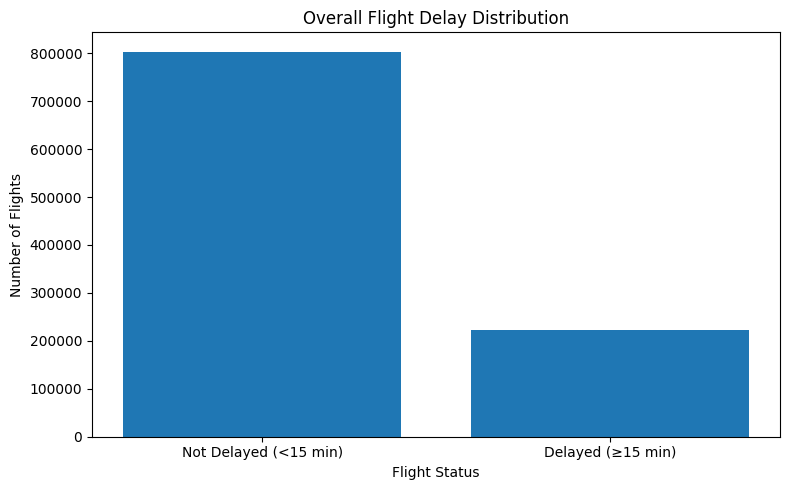

In [23]:
# EDA 1: Overall flight delay distribution

delay_counts = model_df["IsDelayed"].value_counts().sort_index()

labels = ["Not Delayed (<15 min)", "Delayed (≥15 min)"]

plt.figure(figsize=(8, 5))

plt.bar(labels, delay_counts.values)

plt.title("Overall Flight Delay Distribution")
plt.xlabel("Flight Status")
plt.ylabel("Number of Flights")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Interpretation

The majority of flights were not delayed by 15 minutes or more. However, approximately one-fifth of the flights experienced significant arrival delays.

This indicates that flight delay is a meaningful operational problem and supports the need for a predictive system such as FlightIQ.

In [24]:
# EDA 2: Delay rate by airline

airline_delay_rate = (
    model_df.groupby("Airline")["IsDelayed"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print("Delay rate by airline (%):")
display(airline_delay_rate.round(2))

Delay rate by airline (%):


Airline
Allegiant Air                                35.90
JetBlue Airways                              33.95
Frontier Airlines Inc.                       32.54
GoJet Airlines, LLC d/b/a United Express     26.64
Spirit Air Lines                             26.35
Southwest Airlines Co.                       24.72
American Airlines Inc.                       22.66
Comair Inc.                                  22.09
Republic Airlines                            21.79
United Air Lines Inc.                        20.57
Commutair Aka Champlain Enterprises, Inc.    19.71
Alaska Airlines Inc.                         19.68
Mesa Airlines Inc.                           19.15
Delta Air Lines Inc.                         17.38
SkyWest Airlines Inc.                        17.15
Hawaiian Airlines Inc.                       17.11
Horizon Air                                  16.87
Envoy Air                                    16.63
Endeavor Air Inc.                            16.43
Air Wisconsin Airlines 

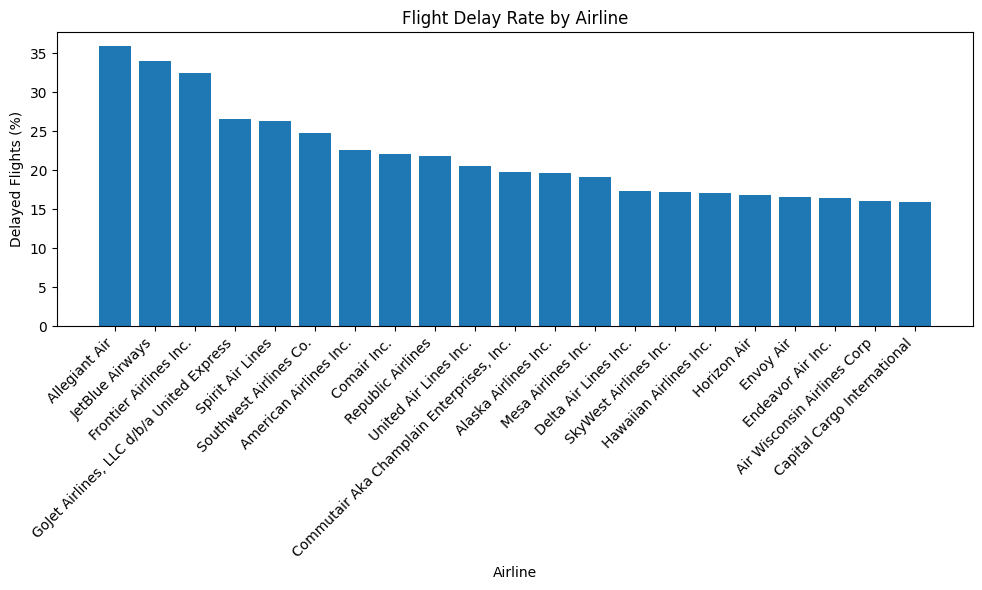

In [25]:
plt.figure(figsize=(10, 6))

plt.bar(
    airline_delay_rate.index,
    airline_delay_rate.values
)

plt.title("Flight Delay Rate by Airline")
plt.xlabel("Airline")
plt.ylabel("Delayed Flights (%)")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Interpretation

The analysis shows substantial variation in delay rates across airlines. In the FlightIQ dataset, the observed delay rate ranges from approximately 15.9% to 35.9%.

Allegiant Air has the highest observed delay rate at 35.90%, followed by JetBlue Airways at 33.95% and Frontier Airlines at 32.54%. Capital Cargo International has the lowest observed rate at 15.91%.

This suggests that the airline operating the flight may be an important predictor of delay risk. However, airline-level delay rates should not be interpreted as the sole cause of delays because other factors such as departure time, route, airport, season, and operational conditions may also influence delays.

In [26]:
# EDA 3: Delay rate by scheduled departure hour

hourly_delay_rate = (
    model_df.groupby("DepartureHour")["IsDelayed"]
    .mean()
    .mul(100)
)

display(hourly_delay_rate.round(2))

DepartureHour
0     23.97
1     20.89
2     28.85
3     21.62
4     22.58
5      8.83
6     10.79
7     12.94
8     14.54
9     16.02
10    17.26
11    18.40
12    19.99
13    22.05
14    24.00
15    26.93
16    27.19
17    28.16
18    28.86
19    30.71
20    30.56
21    31.60
22    29.06
23    24.62
Name: IsDelayed, dtype: float64

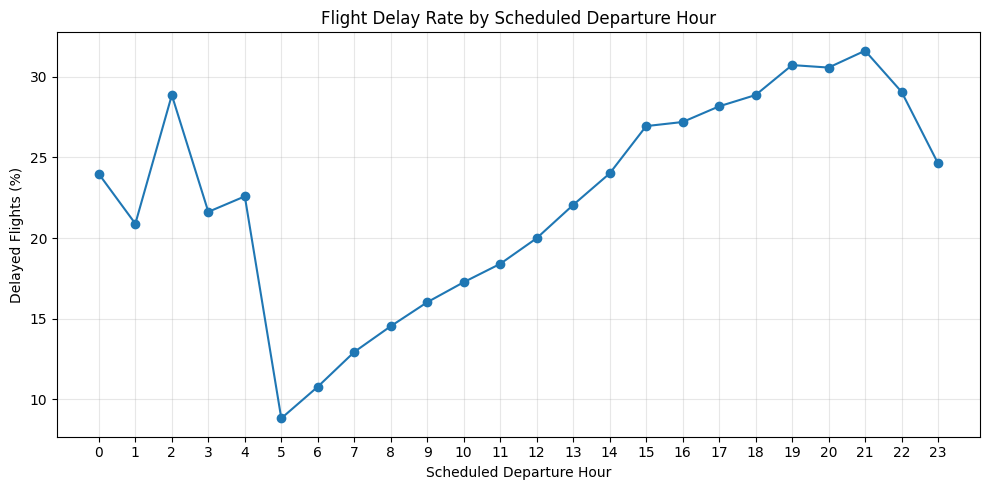

In [27]:
plt.figure(figsize=(10, 5))

plt.plot(
    hourly_delay_rate.index,
    hourly_delay_rate.values,
    marker="o"
)

plt.title("Flight Delay Rate by Scheduled Departure Hour")
plt.xlabel("Scheduled Departure Hour")
plt.ylabel("Delayed Flights (%)")
plt.xticks(range(0, 24))
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [28]:
# EDA 3: Flight volume and delay rate by departure hour

hourly_analysis = model_df.groupby("DepartureHour").agg(
    TotalFlights=("IsDelayed", "count"),
    DelayedFlights=("IsDelayed", "sum"),
    DelayRate=("IsDelayed", "mean")
)

hourly_analysis["DelayRate"] = (
    hourly_analysis["DelayRate"] * 100
).round(2)

display(hourly_analysis)


,TotalFlights,DelayedFlights,DelayRate
DepartureHour,,,
0,2057,493,23.97
1,541,113,20.89
2,253,73,28.85
3,185,40,21.62
4,93,21,22.58
5,25464,2249,8.83
6,71418,7706,10.79
7,68343,8846,12.94
8,70790,10292,14.54


### Interpretation

The analysis shows a clear relationship between scheduled departure time and observed flight delay rate.

Flights scheduled during the early morning generally have lower delay rates. The lowest observed delay rate occurs around 05:00, at 8.83%.

The delay rate generally increases as the scheduled departure time moves later in the day. It reaches 30.71% at 19:00, 30.56% at 20:00, and a maximum of 31.60% at 21:00.

These patterns suggest that scheduled departure hour is an important variable for FlightIQ's pre-departure delay prediction. Later-day flights may be exposed to accumulated operational disruptions, although this analysis shows association rather than causation.

In [29]:
# EDA 4: Delay rate by month

monthly_delay_rate = (
    model_df.groupby("Month")["IsDelayed"]
    .mean()
    .mul(100)
)

monthly_flight_count = (
    model_df.groupby("Month")["IsDelayed"]
    .count()
)

monthly_analysis = pd.DataFrame({
    "TotalFlights": monthly_flight_count,
    "DelayRate": monthly_delay_rate.round(2)
})

display(monthly_analysis)

,TotalFlights,DelayRate
Month,,
1,140785,19.56
2,129788,19.55
3,153264,21.35
4,145263,22.14
5,150616,21.01
6,150758,23.98
7,154526,23.36


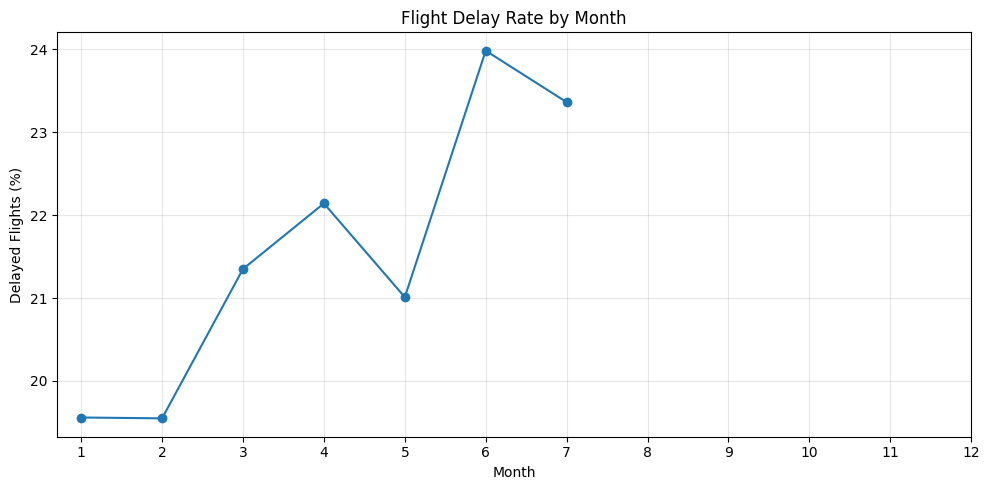

In [30]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_analysis.index,
    monthly_analysis["DelayRate"],
    marker="o"
)

plt.title("Flight Delay Rate by Month")
plt.xlabel("Month")
plt.ylabel("Delayed Flights (%)")
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [31]:
# Verify the date coverage of our modeling dataset

print("Earliest flight date:", model_df["FlightDate"].min())
print("Latest flight date:", model_df["FlightDate"].max())

print("\nMonths present in the dataset:")
print(sorted(model_df["FlightDate"].dt.month.unique()))

Earliest flight date: 2022-01-01 00:00:00
Latest flight date: 2022-07-31 00:00:00

Months present in the dataset:
[np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7)]


### Interpretation

The dataset covers the period from January 1, 2022 to July 31, 2022.

Within this period, the observed delay rate varies across months. January and February have delay rates of approximately 19.6%, while the rate increases during the later months. June has the highest observed delay rate in the available period at 23.98%, followed by July at 23.36%.

This indicates that the month or seasonal period may contain useful information for predicting flight delay risk. However, the findings are limited to the January–July 2022 period represented in the dataset.

In [32]:
# EDA 5: Route-wise delay analysis

route_analysis = model_df.groupby("Route").agg(
    TotalFlights=("IsDelayed", "count"),
    DelayedFlights=("IsDelayed", "sum"),
    DelayRate=("IsDelayed", "mean")
)

route_analysis["DelayRate"] = (
    route_analysis["DelayRate"] * 100
).round(2)

# Consider routes with at least 100 flights
route_analysis_filtered = route_analysis[
    route_analysis["TotalFlights"] >= 100
].sort_values(
    "DelayRate",
    ascending=False
)

print("Number of routes with at least 100 flights:",
      len(route_analysis_filtered))

display(route_analysis_filtered.head(15))

Number of routes with at least 100 flights: 3217


,TotalFlights,DelayedFlights,DelayRate
Route,,,
BDL_SJU,118,63,53.39
TTN_MCO,108,54,50.00
EYW_EWR,119,59,49.58
RSW_BOS,296,137,46.28
BWI_CLE,120,53,44.17
MDW_MEM,102,45,44.12
MCO_BQN,150,66,44.00
DAL_BHM,114,50,43.86
SRQ_EWR,184,80,43.48


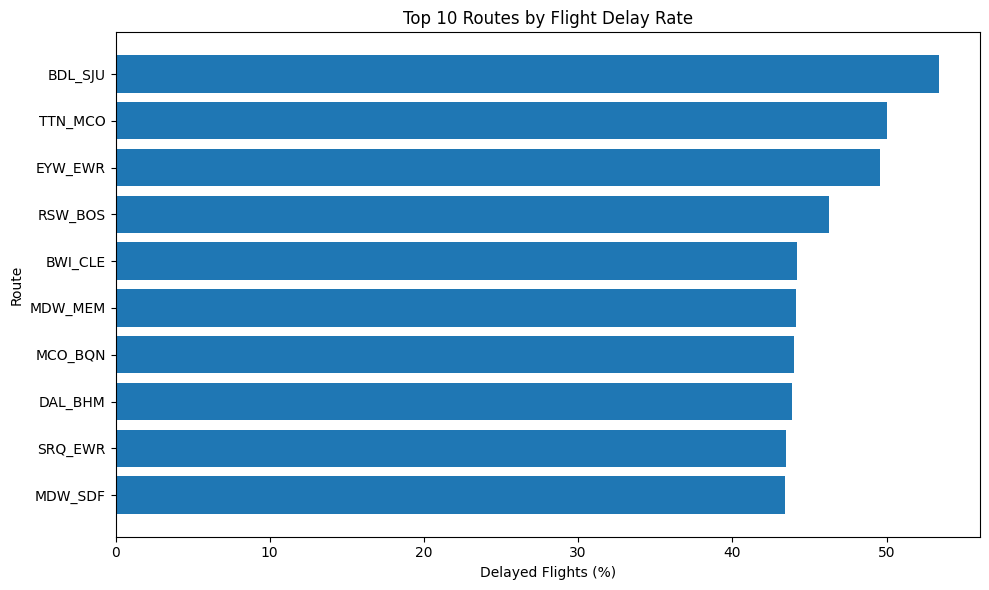

In [33]:
# Top 10 routes by observed delay rate

top_routes = route_analysis_filtered.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_routes.index[::-1],
    top_routes["DelayRate"][::-1]
)

plt.title("Top 10 Routes by Flight Delay Rate")
plt.xlabel("Delayed Flights (%)")
plt.ylabel("Route")

plt.tight_layout()
plt.show()

### Interpretation

The route-level analysis shows substantial variation in observed flight delay rates. Several routes have delay rates above 40%, even after restricting the analysis to routes with at least 100 flights.

This indicates that the origin-destination combination may contain useful information for predicting flight delay risk. Route-level differences may reflect factors such as airport characteristics, traffic conditions, airline operations, and scheduled departure patterns.

The results show association rather than causation; a route itself should not be interpreted as the direct cause of delays.

In [34]:
# EDA 6: Arrival delay duration

delay_summary = model_df["ArrDelayMinutes"].describe()

display(delay_summary)

count    1.025000e+06
mean     1.573749e+01
std      5.166513e+01
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      1.000000e+01
max      7.232000e+03
Name: ArrDelayMinutes, dtype: float64

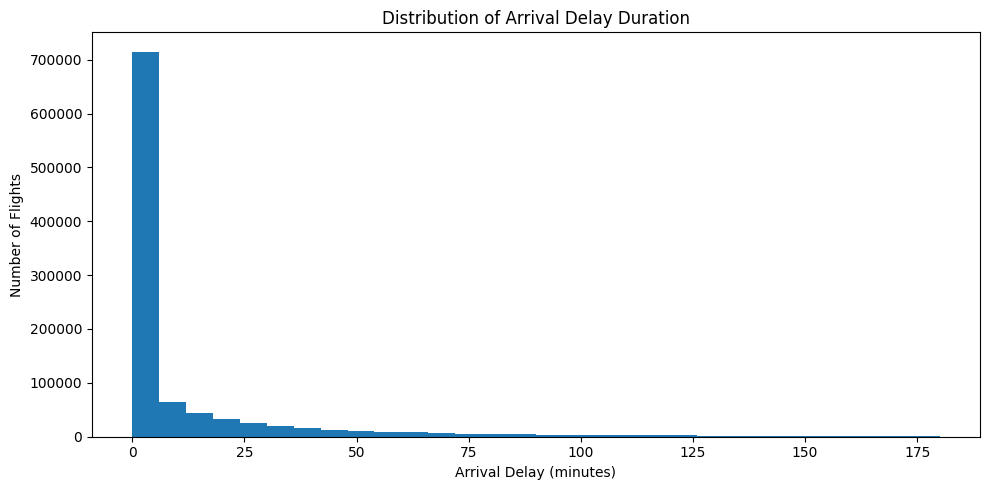

In [35]:
# Distribution of arrival delays up to 180 minutes

delay_plot_data = model_df[
    model_df["ArrDelayMinutes"] <= 180
]["ArrDelayMinutes"]

plt.figure(figsize=(10, 5))

plt.hist(
    delay_plot_data,
    bins=30
)

plt.title("Distribution of Arrival Delay Duration")
plt.xlabel("Arrival Delay (minutes)")
plt.ylabel("Number of Flights")

plt.tight_layout()
plt.show()

### Interpretation

The arrival delay distribution is strongly right-skewed. A large proportion of flights have little or no arrival delay, while the number of flights decreases as the delay duration increases.

The distribution also contains a small number of extreme delay events, resulting in a long right tail. The maximum observed arrival delay in the dataset is 7,232 minutes.

This skewed distribution is important for the Linear Regression model because extreme delay values can have a strong influence on regression performance. Therefore, model evaluation will use multiple metrics rather than relying on a single measure.

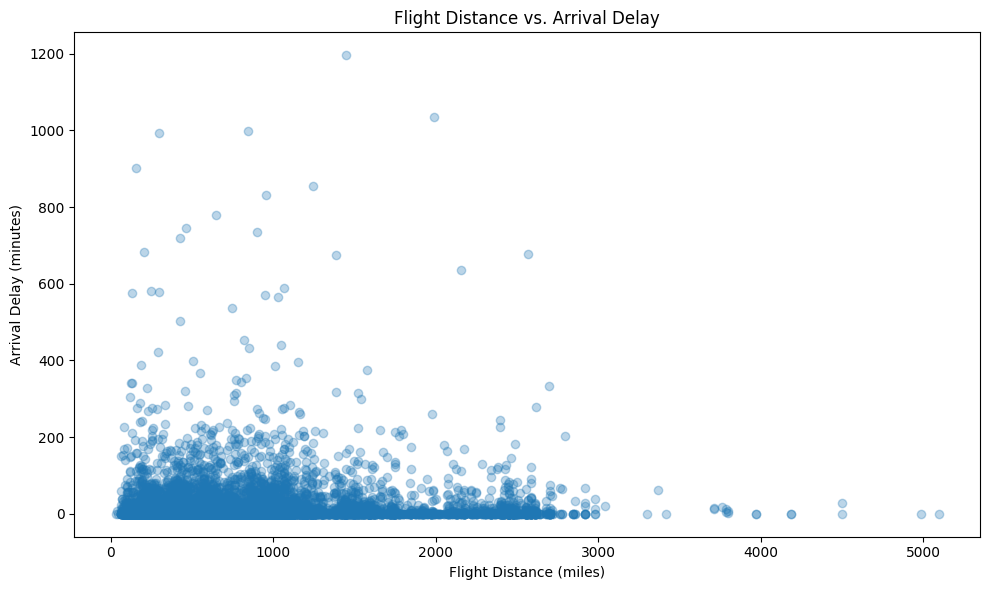

In [36]:
# EDA 7: Flight distance vs. arrival delay

distance_delay_sample = model_df.sample(
    n=10000,
    random_state=42
)

plt.figure(figsize=(10, 6))

plt.scatter(
    distance_delay_sample["Distance"],
    distance_delay_sample["ArrDelayMinutes"],
    alpha=0.3
)

plt.title("Flight Distance vs. Arrival Delay")
plt.xlabel("Flight Distance (miles)")
plt.ylabel("Arrival Delay (minutes)")

plt.tight_layout()
plt.show()

In [37]:
# Calculate correlation between distance and arrival delay

distance_delay_correlation = model_df[
    ["Distance", "ArrDelayMinutes"]
].corr().loc["Distance", "ArrDelayMinutes"]

print(
    "Correlation between flight distance and arrival delay:",
    round(distance_delay_correlation, 4)
)

Correlation between flight distance and arrival delay: 0.0098


### Interpretation

The scatter plot does not show a clear linear relationship between flight distance and arrival delay.

The calculated Pearson correlation coefficient is 0.0098, which is very close to zero. This indicates that flight distance alone has almost no linear association with arrival delay in the available dataset.

However, this does not mean that distance should automatically be removed from the machine learning models. Distance may still provide useful information when combined with other variables such as airline, airport, route, departure time, and scheduled flight duration.

## 4. Exploratory Data Analysis — Summary

The exploratory analysis identified several important patterns in the flight dataset:

1. Approximately 21.63% of flights experienced an arrival delay of at least 15 minutes.

2. Delay rates vary considerably across airlines, ranging from approximately 15.9% to 35.9% in the modeling dataset.

3. Scheduled departure time shows a strong pattern with delay rate. Delay rates generally increase for later-day departures, reaching approximately 31.6% around 21:00.

4. Within the January–July 2022 period represented in the dataset, delay rates vary by month, with June showing the highest observed rate at 23.98%.

5. Delay rates also vary substantially across routes, indicating that the origin-destination combination may contain useful predictive information.

6. Arrival delay duration is strongly right-skewed, with most flights having little or no delay and a smaller number experiencing very large delays.

7. Flight distance has almost no linear relationship with arrival delay, with a Pearson correlation of 0.0098. However, distance may still provide useful information when combined with other features.

These findings provide a basis for selecting and engineering features for the FlightIQ prediction models.

# 5. Feature Engineering & Selection

The goal of feature engineering is to transform the cleaned flight data into meaningful variables that can be used by the FlightIQ machine learning models.

Since FlightIQ makes predictions before the scheduled departure of a flight, feature selection follows a strict pre-departure rule.

Only information available before departure is considered as a model input.

The feature engineering process includes:

1. Creating time-based features from scheduled departure and arrival times.
2. Creating calendar-based features from the flight date.
3. Representing the origin and destination airports.
4. Representing airline information.
5. Representing route information.
6. Selecting numerical and categorical predictors.
7. Removing redundant identifiers.
8. Removing post-departure variables to prevent data leakage.

In [38]:
# Current features in the modeling dataset

print("Current number of columns:", len(model_df.columns))

for i, column in enumerate(model_df.columns, start=1):
    print(f"{i}. {column}")

Current number of columns: 28
1. FlightDate
2. Airline
3. Origin
4. Dest
5. Cancelled
6. Diverted
7. CRSDepTime
8. ArrDelayMinutes
9. CRSElapsedTime
10. Distance
11. Month
12. DayofMonth
13. DayOfWeek
14. Marketing_Airline_Network
15. Operating_Airline
16. OriginAirportID
17. DestAirportID
18. DepTimeBlk
19. CRSArrTime
20. ArrTimeBlk
21. DistanceGroup
22. IsDelayed
23. DayOfYear
24. WeekOfYear
25. DepartureHour
26. DepartureMinute
27. ArrivalHour
28. Route


In [39]:
# Define FlightIQ prediction targets

regression_target = "ArrDelayMinutes"
classification_target = "IsDelayed"

print("Regression target:", regression_target)
print("Classification target:", classification_target)

Regression target: ArrDelayMinutes
Classification target: IsDelayed


In [40]:
# Variables that are not available before departure
# and therefore must not be used as prediction features

leakage_columns = [
    "DepTime",
    "DepDelayMinutes",
    "DepDelay",
    "ArrTime",
    "AirTime",
    "ActualElapsedTime",
    "DepDel15",
    "DepartureDelayGroups",
    "TaxiOut",
    "WheelsOff",
    "WheelsOn",
    "TaxiIn",
    "ArrDelay",
    "ArrDel15",
    "ArrivalDelayGroups",
    "DivAirportLandings"
]

print("Post-departure / leakage variables:")
for column in leakage_columns:
    print("-", column)

Post-departure / leakage variables:
- DepTime
- DepDelayMinutes
- DepDelay
- ArrTime
- AirTime
- ActualElapsedTime
- DepDel15
- DepartureDelayGroups
- TaxiOut
- WheelsOff
- WheelsOn
- TaxiIn
- ArrDelay
- ArrDel15
- ArrivalDelayGroups
- DivAirportLandings


In [41]:
# Candidate pre-departure features

candidate_features = [
    "Airline",
    "Origin",
    "Dest",
    "CRSDepTime",
    "CRSArrTime",
    "CRSElapsedTime",
    "Distance",
    "Month",
    "DayofMonth",
    "DayOfWeek",
    "Marketing_Airline_Network",
    "Operating_Airline",
    "OriginAirportID",
    "DestAirportID",
    "DepTimeBlk",
    "ArrTimeBlk",
    "DistanceGroup",
    "DepartureHour",
    "DepartureMinute",
    "ArrivalHour",
    "DayOfYear",
    "WeekOfYear",
    "Route"
]

print("Number of candidate features:", len(candidate_features))

for feature in candidate_features:
    print("-", feature)

Number of candidate features: 23
- Airline
- Origin
- Dest
- CRSDepTime
- CRSArrTime
- CRSElapsedTime
- Distance
- Month
- DayofMonth
- DayOfWeek
- Marketing_Airline_Network
- Operating_Airline
- OriginAirportID
- DestAirportID
- DepTimeBlk
- ArrTimeBlk
- DistanceGroup
- DepartureHour
- DepartureMinute
- ArrivalHour
- DayOfYear
- WeekOfYear
- Route


In [42]:
# Check the number of unique values for candidate features

feature_cardinality = pd.DataFrame({
    "Feature": candidate_features,
    "UniqueValues": [
        model_df[feature].nunique()
        for feature in candidate_features
    ]
})

display(
    feature_cardinality.sort_values(
        "UniqueValues",
        ascending=False
    )
)

,Feature,UniqueValues
22,Route,6747
6,Distance,1574
4,CRSArrTime,1379
3,CRSDepTime,1292
5,CRSElapsedTime,536
12,OriginAirportID,375
1,Origin,375
13,DestAirportID,374
2,Dest,374
20,DayOfYear,212


In [43]:
# Check correlations among numerical candidate features

numeric_features = [
    "CRSDepTime",
    "CRSArrTime",
    "CRSElapsedTime",
    "Distance",
    "Month",
    "DayofMonth",
    "DayOfWeek",
    "OriginAirportID",
    "DestAirportID",
    "DistanceGroup",
    "DepartureHour",
    "DepartureMinute",
    "ArrivalHour",
    "DayOfYear",
    "WeekOfYear"
]

correlation_matrix = model_df[numeric_features].corr()

display(correlation_matrix.round(2))

,CRSDepTime,CRSArrTime,CRSElapsedTime,Distance,Month,DayofMonth,DayOfWeek,OriginAirportID,DestAirportID,DistanceGroup,DepartureHour,DepartureMinute,ArrivalHour,DayOfYear,WeekOfYear
CRSDepTime,1.00,0.69,-0.01,-0.00,0.00,-0.00,0.00,-0.03,0.03,-0.00,1.00,0.15,0.68,0.00,0.01
CRSArrTime,0.69,1.00,0.02,0.02,-0.02,-0.00,0.00,-0.01,0.02,0.03,0.68,0.11,1.00,-0.02,-0.01
CRSElapsedTime,-0.01,0.02,1.00,0.98,-0.03,-0.00,0.01,0.06,0.08,0.97,-0.01,0.01,0.02,-0.03,-0.02
Distance,-0.00,0.02,0.98,1.00,-0.00,-0.00,0.01,0.08,0.08,0.99,-0.00,0.01,0.02,-0.00,-0.00
Month,0.00,-0.02,-0.03,-0.00,1.00,0.00,0.02,-0.00,0.00,-0.00,0.00,-0.00,-0.02,0.99,0.86
DayofMonth,-0.00,-0.00,-0.00,-0.00,0.00,1.00,-0.00,-0.00,0.00,-0.00,0.00,-0.00,-0.00,0.15,0.06
DayOfWeek,0.00,0.00,0.01,0.01,0.02,-0.00,1.00,0.00,0.00,0.01,0.00,0.00,0.00,0.02,0.04
OriginAirportID,-0.03,-0.01,0.06,0.08,-0.00,-0.00,0.00,1.00,0.01,0.08,-0.03,0.00,-0.01,-0.00,-0.00
DestAirportID,0.03,0.02,0.08,0.08,0.00,0.00,0.00,0.01,1.00,0.08,0.03,0.01,0.02,0.00,-0.00
DistanceGroup,-0.00,0.03,0.97,0.99,-0.00,-0.00,0.01,0.08,0.08,1.00,-0.00,0.01,0.03,-0.01,-0.00


In [44]:
# Final pre-departure features selected for FlightIQ

final_features = [
    "Airline",
    "Origin",
    "Dest",
    "CRSElapsedTime",
    "Month",
    "DayOfWeek",
    "Operating_Airline",
    "DepTimeBlk",
    "ArrTimeBlk",
    "DepartureHour",
    "DepartureMinute",
    "ArrivalHour"
]

print("Number of final features:", len(final_features))

print("\nFinal FlightIQ features:")
for i, feature in enumerate(final_features, start=1):
    print(f"{i}. {feature}")

Number of final features: 12

Final FlightIQ features:
1. Airline
2. Origin
3. Dest
4. CRSElapsedTime
5. Month
6. DayOfWeek
7. Operating_Airline
8. DepTimeBlk
9. ArrTimeBlk
10. DepartureHour
11. DepartureMinute
12. ArrivalHour


In [45]:
# Create feature matrix and prediction targets

X = model_df[final_features].copy()

y_classification = model_df["IsDelayed"].copy()

y_regression = model_df["ArrDelayMinutes"].copy()

print("Feature matrix shape:", X.shape)
print("Classification target shape:", y_classification.shape)
print("Regression target shape:", y_regression.shape)

Feature matrix shape: (1025000, 12)
Classification target shape: (1025000,)
Regression target shape: (1025000,)


In [46]:
# Verify that no target or post-departure variables are included

forbidden_features = [
    "ArrDelayMinutes",
    "IsDelayed",
    "DepTime",
    "DepDelayMinutes",
    "DepDelay",
    "ArrTime",
    "ArrDelay",
    "AirTime",
    "ActualElapsedTime",
    "DepDel15",
    "ArrDel15"
]

leakage_in_features = [
    feature for feature in final_features
    if feature in forbidden_features
]

print("Features checked:", len(final_features))
print("Leakage variables found:", leakage_in_features)

if len(leakage_in_features) == 0:
    print("✓ No target or post-departure leakage detected.")

Features checked: 12
Leakage variables found: []
✓ No target or post-departure leakage detected.


### Final Feature Selection Decision

After evaluating feature cardinality, redundancy, correlation, domain relevance, and the pre-departure prediction requirement, 12 features were selected for the FlightIQ models.

The selected features represent airline characteristics, origin and destination airports, scheduled flight duration, calendar information, scheduled departure and arrival periods, and detailed scheduled departure timing.

Highly redundant features were removed. For example, airport IDs were removed because the corresponding airport codes already represent the same information. DistanceGroup was removed because it is highly correlated with Distance, while Distance was excluded in favor of CRSElapsedTime because the two variables have a correlation of approximately 0.98.

Raw scheduled time fields were replaced by engineered hour/minute features where appropriate.

Route was retained in the dataset for analysis and future application use but excluded from the initial model feature matrix because it contains 6,747 unique categories and would substantially increase the dimensionality of one-hot encoded models.

Most importantly, post-departure information and target-derived variables were excluded to ensure that FlightIQ performs genuine pre-departure prediction without data leakage.

## 6.1 Time-Based Train, Validation and Test Split

Since FlightIQ is designed for real-world pre-departure prediction, the dataset is split chronologically rather than randomly.

- Training data: January–May 2022
- Validation data: June 2022
- Testing data: July 2022

This prevents future flight information from being used to train the model when evaluating its performance on later flights.

In [48]:
# Create time-based train, validation and test datasets

train_mask = model_df["FlightDate"].dt.month <= 5
validation_mask = model_df["FlightDate"].dt.month == 6
test_mask = model_df["FlightDate"].dt.month == 7

X_train = model_df.loc[train_mask, final_features].copy()
X_validation = model_df.loc[validation_mask, final_features].copy()
X_test = model_df.loc[test_mask, final_features].copy()

y_class_train = model_df.loc[train_mask, "IsDelayed"].copy()
y_class_validation = model_df.loc[validation_mask, "IsDelayed"].copy()
y_class_test = model_df.loc[test_mask, "IsDelayed"].copy()

y_reg_train = model_df.loc[train_mask, "ArrDelayMinutes"].copy()
y_reg_validation = model_df.loc[validation_mask, "ArrDelayMinutes"].copy()
y_reg_test = model_df.loc[test_mask, "ArrDelayMinutes"].copy()

print("Training set:", X_train.shape)
print("Validation set:", X_validation.shape)
print("Testing set:", X_test.shape)

Training set: (719716, 12)
Validation set: (150758, 12)
Testing set: (154526, 12)


## 6.2 Machine Learning Preprocessing

The selected features contain both numerical and categorical variables.

- Numerical features are imputed if necessary and standardized.
- Categorical features are imputed if necessary and converted into numerical form using One-Hot Encoding.
- The preprocessing pipeline is fitted only on the training data to prevent information leakage from the validation and test sets.
- The same fitted preprocessing transformation is then applied to validation and test data.

In [49]:
# Machine learning preprocessing

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Separate numerical and categorical features
numeric_features = [
    "CRSElapsedTime",
    "Month",
    "DayOfWeek",
    "DepartureHour",
    "DepartureMinute",
    "ArrivalHour"
]

categorical_features = [
    "Airline",
    "Origin",
    "Dest",
    "Operating_Airline",
    "DepTimeBlk",
    "ArrTimeBlk"
]

# Numerical preprocessing
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Preprocessing pipeline created successfully!")

Numerical features: 6
Categorical features: 6
Preprocessing pipeline created successfully!


In [50]:
# Fit preprocessing only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same preprocessing to validation and test data
X_validation_processed = preprocessor.transform(X_validation)
X_test_processed = preprocessor.transform(X_test)

print("Training data after preprocessing:", X_train_processed.shape)
print("Validation data after preprocessing:", X_validation_processed.shape)
print("Testing data after preprocessing:", X_test_processed.shape)

Training data after preprocessing: (719716, 834)
Validation data after preprocessing: (150758, 834)
Testing data after preprocessing: (154526, 834)


## 6.3 Logistic Regression — Flight Delay Classification

Logistic Regression is used to classify flights into two categories:

- 0 → Not delayed (< 15 minutes)
- 1 → Delayed (≥ 15 minutes)

The model estimates the probability that a flight will be delayed using only pre-departure features.

In [51]:
# Train Logistic Regression model

from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(
    X_train_processed,
    y_class_train
)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [52]:
# Generate predictions on the validation dataset

y_class_validation_pred = logistic_model.predict(X_validation_processed)

# Predicted probabilities for the delayed class
y_class_validation_prob = logistic_model.predict_proba(
    X_validation_processed
)[:, 1]

print("Validation predictions generated successfully!")

print("Number of predictions:", len(y_class_validation_pred))
print("First 10 predicted classes:", y_class_validation_pred[:10])
print("First 10 delay probabilities:", y_class_validation_prob[:10])

Validation predictions generated successfully!
Number of predictions: 150758
First 10 predicted classes: [0 0 0 0 0 0 0 0 0 0]
First 10 delay probabilities: [0.25823923 0.11451744 0.1887054  0.34079    0.18896955 0.25577833
 0.24406116 0.1486407  0.42338622 0.08277406]


## 6.4 Decision Tree — Flight Delay Classification

A Decision Tree classifier is used to predict whether a flight will be delayed by 15 minutes or more.

The Decision Tree also provides feature importance, helping FlightIQ identify which pre-departure factors contribute most to delay classification.

In [53]:
# Train Decision Tree classifier

from sklearn.tree import DecisionTreeClassifier

decision_tree_model = DecisionTreeClassifier(
    max_depth=10,
    random_state=42
)

decision_tree_model.fit(
    X_train_processed,
    y_class_train
)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [54]:
# Generate Decision Tree predictions on the validation dataset

y_tree_validation_pred = decision_tree_model.predict(
    X_validation_processed
)

y_tree_validation_prob = decision_tree_model.predict_proba(
    X_validation_processed
)[:, 1]

print("Decision Tree validation predictions generated successfully!")

print("Number of predictions:", len(y_tree_validation_pred))
print("First 10 predicted classes:", y_tree_validation_pred[:10])
print("First 10 delay probabilities:", y_tree_validation_prob[:10])

Decision Tree validation predictions generated successfully!
Number of predictions: 150758
First 10 predicted classes: [0 0 0 0 0 0 0 0 0 0]
First 10 delay probabilities: [0.2298125  0.09331675 0.14420063 0.16687818 0.17738901 0.16687818
 0.20207459 0.16687818 0.2298125  0.11797231]


## 6.5 Linear Regression — Arrival Delay Duration Prediction

Linear Regression is used to predict the expected arrival delay duration in minutes.

Target variable:
- ArrDelayMinutes

The model uses only pre-departure flight information as input features.

In [55]:
# Train Linear Regression model

from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(
    X_train_processed,
    y_reg_train
)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [56]:
# Generate Linear Regression predictions on the validation dataset

y_reg_validation_pred = linear_model.predict(
    X_validation_processed
)

print("Linear Regression validation predictions generated successfully!")

print("Number of predictions:", len(y_reg_validation_pred))
print(
    "First 10 actual delay values:",
    y_reg_validation.head(10).to_numpy()
)
print(
    "First 10 predicted delay values:",
    y_reg_validation_pred[:10]
)

Linear Regression validation predictions generated successfully!
Number of predictions: 150758
First 10 actual delay values: [ 0.  0. 16.  0.  0.  0. 80.  0.  0.  3.]
First 10 predicted delay values: [21.93659759 12.17226252 13.47884621 25.55932678  9.7652478  22.63704183
 26.70194575  9.88552493 34.19341856 12.30092638]


## 7.1 Logistic Regression — Classification Evaluation

The Logistic Regression model is evaluated using the validation dataset.

The confusion matrix shows:
- True Negatives (TN)
- False Positives (FP)
- False Negatives (FN)
- True Positives (TP)

Additional evaluation metrics include accuracy, precision, recall, F1-score and ROC-AUC.

In [57]:
# Evaluate Logistic Regression on validation data

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Confusion matrix
logistic_cm = confusion_matrix(
    y_class_validation,
    y_class_validation_pred
)

print("Logistic Regression Confusion Matrix:")
print(logistic_cm)

# Classification metrics
logistic_accuracy = accuracy_score(
    y_class_validation,
    y_class_validation_pred
)

logistic_precision = precision_score(
    y_class_validation,
    y_class_validation_pred
)

logistic_recall = recall_score(
    y_class_validation,
    y_class_validation_pred
)

logistic_f1 = f1_score(
    y_class_validation,
    y_class_validation_pred
)

logistic_roc_auc = roc_auc_score(
    y_class_validation,
    y_class_validation_prob
)

print("\nLogistic Regression Metrics:")
print("Accuracy :", round(logistic_accuracy, 4))
print("Precision:", round(logistic_precision, 4))
print("Recall   :", round(logistic_recall, 4))
print("F1-score :", round(logistic_f1, 4))
print("ROC-AUC  :", round(logistic_roc_auc, 4))

Logistic Regression Confusion Matrix:
[[114006    601]
 [ 35463    688]]

Logistic Regression Metrics:
Accuracy : 0.7608
Precision: 0.5337
Recall   : 0.019
F1-score : 0.0368
ROC-AUC  : 0.6579


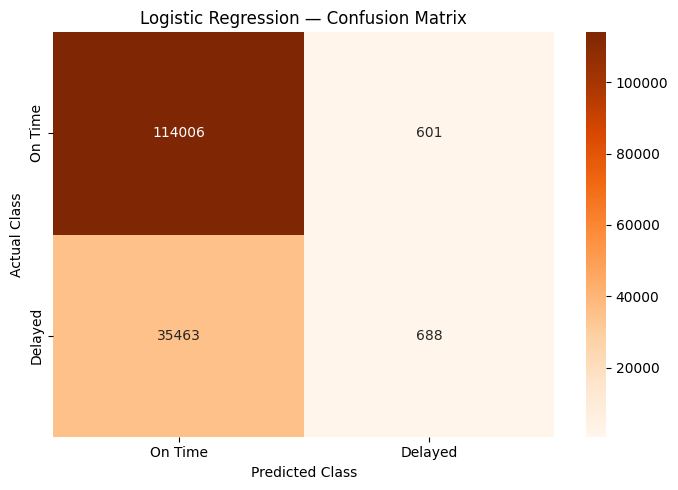

In [61]:
# Plot Logistic Regression confusion matrix

plt.figure(figsize=(7, 5))

sns.heatmap(
    logistic_cm,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["On Time", "Delayed"],
    yticklabels=["On Time", "Delayed"]
)

plt.title("Logistic Regression — Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

In [62]:
# Evaluate Decision Tree classifier

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Calculate confusion matrix
tree_cm = confusion_matrix(
    y_class_validation,
    y_tree_validation_pred
)

# Calculate classification metrics
tree_accuracy = accuracy_score(
    y_class_validation,
    y_tree_validation_pred
)

tree_precision = precision_score(
    y_class_validation,
    y_tree_validation_pred,
    zero_division=0
)

tree_recall = recall_score(
    y_class_validation,
    y_tree_validation_pred,
    zero_division=0
)

tree_f1 = f1_score(
    y_class_validation,
    y_tree_validation_pred,
    zero_division=0
)

tree_roc_auc = roc_auc_score(
    y_class_validation,
    y_tree_validation_prob
)

print("Decision Tree Confusion Matrix:")
print(tree_cm)

print("\nDecision Tree Metrics:")
print("Accuracy :", round(tree_accuracy, 4))
print("Precision:", round(tree_precision, 4))
print("Recall   :", round(tree_recall, 4))
print("F1-score :", round(tree_f1, 4))
print("ROC-AUC  :", round(tree_roc_auc, 4))

Decision Tree Confusion Matrix:
[[111798   2809]
 [ 33367   2784]]

Decision Tree Metrics:
Accuracy : 0.76
Precision: 0.4978
Recall   : 0.077
F1-score : 0.1334
ROC-AUC  : 0.6484


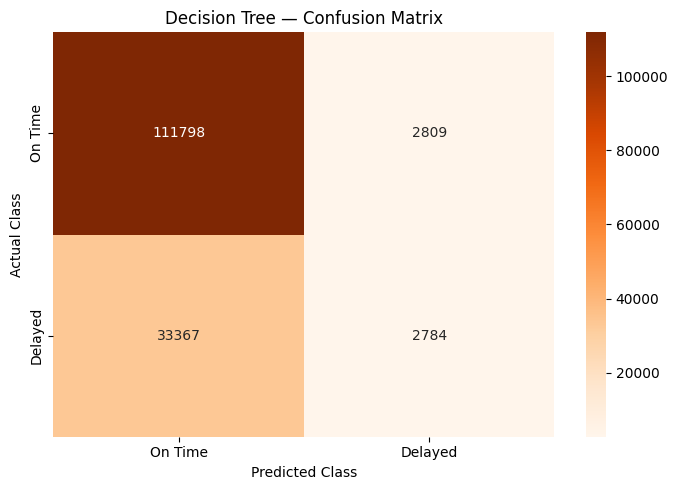

In [63]:
# Plot Decision Tree confusion matrix

plt.figure(figsize=(7, 5))

sns.heatmap(
    tree_cm,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["On Time", "Delayed"],
    yticklabels=["On Time", "Delayed"]
)

plt.title("Decision Tree — Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

In [64]:
# Display Decision Tree evaluation metrics

print("Decision Tree Metrics:")
print("Accuracy :", round(tree_accuracy, 4))
print("Precision:", round(tree_precision, 4))
print("Recall   :", round(tree_recall, 4))
print("F1-score :", round(tree_f1, 4))
print("ROC-AUC  :", round(tree_roc_auc, 4))

Decision Tree Metrics:
Accuracy : 0.76
Precision: 0.4978
Recall   : 0.077
F1-score : 0.1334
ROC-AUC  : 0.6484


In [65]:
# Compare classification models

classification_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree"
    ],
    "Accuracy": [
        logistic_accuracy,
        tree_accuracy
    ],
    "Precision": [
        logistic_precision,
        tree_precision
    ],
    "Recall": [
        logistic_recall,
        tree_recall
    ],
    "F1-Score": [
        logistic_f1,
        tree_f1
    ],
    "ROC-AUC": [
        logistic_roc_auc,
        tree_roc_auc
    ]
})

display(classification_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.7608,0.5337,0.019,0.0368,0.6579
1,Decision Tree,0.7600,0.4978,0.077,0.1334,0.6484


In [66]:
# Evaluate Linear Regression model

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate regression metrics
linear_mae = mean_absolute_error(
    y_reg_validation,
    y_reg_validation_pred
)

linear_rmse = np.sqrt(
    mean_squared_error(
        y_reg_validation,
        y_reg_validation_pred
    )
)

linear_r2 = r2_score(
    y_reg_validation,
    y_reg_validation_pred
)

print("Linear Regression Metrics:")
print("MAE :", round(linear_mae, 4))
print("RMSE:", round(linear_rmse, 4))
print("R²  :", round(linear_r2, 4))

Linear Regression Metrics:
MAE : 23.1879
RMSE: 55.71
R²  : 0.0161


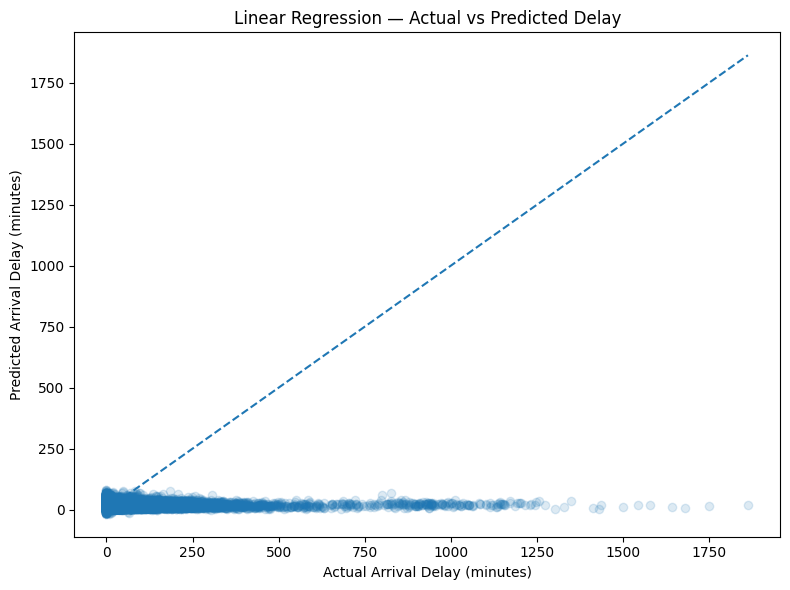

In [67]:
# Actual vs Predicted Arrival Delay

plt.figure(figsize=(8, 6))

plt.scatter(
    y_reg_validation,
    y_reg_validation_pred,
    alpha=0.15
)

# Perfect prediction reference line
max_value = max(
    y_reg_validation.max(),
    y_reg_validation_pred.max()
)

plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle="--"
)

plt.title("Linear Regression — Actual vs Predicted Delay")
plt.xlabel("Actual Arrival Delay (minutes)")
plt.ylabel("Predicted Arrival Delay (minutes)")

plt.tight_layout()
plt.show()

In [68]:
# Final Logistic Regression evaluation on the test dataset

y_class_test_pred = logistic_model.predict(X_test_processed)
y_class_test_prob = logistic_model.predict_proba(X_test_processed)[:, 1]

print("Final Logistic Regression Test Accuracy:",
      round(accuracy_score(y_class_test, y_class_test_pred), 4))

print("Final Logistic Regression Test Precision:",
      round(precision_score(y_class_test, y_class_test_pred, zero_division=0), 4))

print("Final Logistic Regression Test Recall:",
      round(recall_score(y_class_test, y_class_test_pred, zero_division=0), 4))

print("Final Logistic Regression Test F1-Score:",
      round(f1_score(y_class_test, y_class_test_pred, zero_division=0), 4))

print("Final Logistic Regression Test ROC-AUC:",
      round(roc_auc_score(y_class_test, y_class_test_prob), 4))

Final Logistic Regression Test Accuracy: 0.7657
Final Logistic Regression Test Precision: 0.4709
Final Logistic Regression Test Recall: 0.0242
Final Logistic Regression Test F1-Score: 0.0461
Final Logistic Regression Test ROC-AUC: 0.6544


In [69]:
# Final Decision Tree evaluation on the test dataset

y_tree_test_pred = decision_tree_model.predict(X_test_processed)
y_tree_test_prob = decision_tree_model.predict_proba(X_test_processed)[:, 1]

print("Final Decision Tree Test Accuracy:",
      round(accuracy_score(y_class_test, y_tree_test_pred), 4))

print("Final Decision Tree Test Precision:",
      round(precision_score(y_class_test, y_tree_test_pred, zero_division=0), 4))

print("Final Decision Tree Test Recall:",
      round(recall_score(y_class_test, y_tree_test_pred, zero_division=0), 4))

print("Final Decision Tree Test F1-Score:",
      round(f1_score(y_class_test, y_tree_test_pred, zero_division=0), 4))

print("Final Decision Tree Test ROC-AUC:",
      round(roc_auc_score(y_class_test, y_tree_test_prob), 4))

Final Decision Tree Test Accuracy: 0.7615
Final Decision Tree Test Precision: 0.4385
Final Decision Tree Test Recall: 0.0747
Final Decision Tree Test F1-Score: 0.1277
Final Decision Tree Test ROC-AUC: 0.6467


In [70]:
# Final Linear Regression evaluation on the test dataset

y_reg_test_pred = linear_model.predict(X_test_processed)

linear_test_mae = mean_absolute_error(
    y_reg_test,
    y_reg_test_pred
)

linear_test_rmse = np.sqrt(
    mean_squared_error(y_reg_test, y_reg_test_pred)
)

linear_test_r2 = r2_score(
    y_reg_test,
    y_reg_test_pred
)

print("Final Linear Regression Test Results:")
print("MAE :", round(linear_test_mae, 4))
print("RMSE:", round(linear_test_rmse, 4))
print("R²  :", round(linear_test_r2, 4))

Final Linear Regression Test Results:
MAE : 23.3053
RMSE: 53.0806
R²  : 0.0134


In [71]:
# Final model comparison

final_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Linear Regression"
    ],
    "Task": [
        "Classification",
        "Classification",
        "Regression"
    ],
    "Primary Metric": [
        f"ROC-AUC = {roc_auc_score(y_class_test, y_class_test_prob):.4f}",
        f"ROC-AUC = {roc_auc_score(y_class_test, y_tree_test_prob):.4f}",
        f"R² = {linear_test_r2:.4f}"
    ]
})

display(final_comparison)

,Model,Task,Primary Metric
0,Logistic Regression,Classification,ROC-AUC = 0.6544
1,Decision Tree,Classification,ROC-AUC = 0.6467
2,Linear Regression,Regression,R² = 0.0134


In [73]:
# Decision Tree Feature Importance after One-Hot Encoding

# Get the actual feature names created by the preprocessing pipeline
encoded_feature_names = preprocessor.get_feature_names_out()

# Get feature importance from the trained Decision Tree
importance_values = decision_tree_model.feature_importances_

print("Number of encoded features:", len(encoded_feature_names))
print("Number of importance values:", len(importance_values))

# Create feature importance table
feature_importance = pd.DataFrame({
    "Feature": encoded_feature_names,
    "Importance": importance_values
})

# Sort from highest to lowest importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("\nTop 20 Decision Tree Features:")
display(feature_importance.head(20))

Number of encoded features: 834
Number of importance values: 834

Top 20 Decision Tree Features:


,Feature,Importance
0,num__DepartureHour,0.284624
1,num__DayOfWeek,0.106817
2,num__Month,0.088593
3,cat__Operating_Airline_B6,0.055340
4,cat__Airline_Southwest Airlines Co.,0.052177
5,num__ArrivalHour,0.049803
6,cat__Operating_Airline_G4,0.042524
7,cat__Operating_Airline_F9,0.042253
8,num__CRSElapsedTime,0.033426
9,cat__Dest_EWR,0.030590


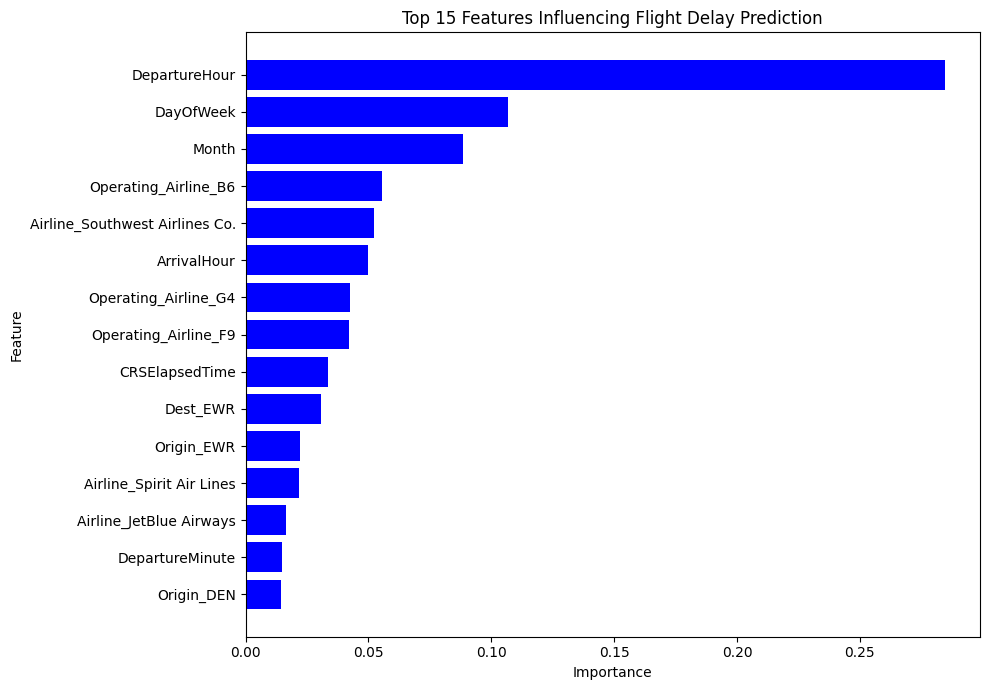

In [75]:
# Plot Top 15 Decision Tree Feature Importances

top_features = feature_importance.head(15).copy()

# Make feature names easier to read
top_features["Feature"] = (
    top_features["Feature"]
    .str.replace("num__", "", regex=False)
    .str.replace("cat__", "", regex=False)
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1],
    color="blue"
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 Features Influencing Flight Delay Prediction")

plt.tight_layout()
plt.show()

## 8. Business Insights & Recommendations

### Key Findings

1. **Departure time is the most influential feature**
   - The Decision Tree assigned the highest importance to DepartureHour.
   - This indicates that delay risk varies considerably throughout the day.

2. **Day of week affects delay patterns**
   - Different days show different levels of delay risk.
   - This can help passengers and airline planners identify higher-risk travel periods.

3. **Seasonality matters**
   - Month was one of the most important features.
   - Delay patterns vary across different months of the year.

4. **Airline operations influence delay risk**
   - Several operating airlines appeared among the important Decision Tree features.
   - This suggests that operational patterns differ between carriers.

5. **Airport characteristics matter**
   - Some origin and destination airports appeared among the important features.
   - Airport-specific operational conditions may contribute to different delay patterns.

### Business Recommendations

- Airlines can use delay-risk predictions for better operational planning.
- Passengers can use the risk score to choose lower-risk departure periods when alternatives are available.
- Airport and airline teams can prioritize high-risk time periods for operational monitoring.
- FlightIQ can provide an early warning system before scheduled departure.

### Important Limitation

Feature importance indicates which variables were useful to the model for making predictions. It does not prove that these variables directly cause flight delays.

# 9. Final Model Evaluation & Validation

The final models are evaluated on the previously unseen test dataset.

Classification models are evaluated using Accuracy, Precision, Recall, F1-Score and ROC-AUC.

The regression model is evaluated using MAE, RMSE and R².

The test dataset was not used during model training, allowing an unbiased assessment of final model performance.

In [76]:
# Final test performance summary

final_evaluation = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Linear Regression"
    ],
    
    "Task": [
        "Classification",
        "Classification",
        "Regression"
    ],
    
    "Accuracy": [
        0.7657,
        0.7615,
        np.nan
    ],
    
    "Precision": [
        0.4709,
        0.4385,
        np.nan
    ],
    
    "Recall": [
        0.0242,
        0.0747,
        np.nan
    ],
    
    "F1-Score": [
        0.0461,
        0.1277,
        np.nan
    ],
    
    "ROC-AUC": [
        0.6544,
        0.6467,
        np.nan
    ],
    
    "MAE": [
        np.nan,
        np.nan,
        23.3053
    ],
    
    "RMSE": [
        np.nan,
        np.nan,
        53.0806
    ],
    
    "R²": [
        np.nan,
        np.nan,
        0.0134
    ]
})

display(final_evaluation.round(4))

,Model,Task,Accuracy,Precision,Recall,F1-Score,ROC-AUC,MAE,RMSE,R²
0,Logistic Regression,Classification,0.7657,0.4709,0.0242,0.0461,0.6544,NaN,NaN,NaN
1,Decision Tree,Classification,0.7615,0.4385,0.0747,0.1277,0.6467,NaN,NaN,NaN
2,Linear Regression,Regression,NaN,NaN,NaN,NaN,NaN,23.3053,53.0806,0.0134


## Final Evaluation Interpretation

### Classification

Logistic Regression achieved the highest accuracy and ROC-AUC among the two classification models.

However, Decision Tree achieved a higher Recall and F1-Score, meaning it identified more of the actually delayed flights.

Because the dataset contains substantially more on-time flights than delayed flights, accuracy alone is not sufficient for evaluating delay detection.

### Regression

Linear Regression achieved an MAE of approximately 23.31 minutes.

However, its R² value of 0.0134 indicates that the linear model explains only a small portion of the variation in arrival delay duration.

This indicates that flight delay duration is influenced by complex and potentially non-linear factors that cannot be adequately captured by a simple linear relationship.

### Overall Conclusion

The classification models provide useful baseline delay-risk predictions, while the Decision Tree provides additional interpretability through feature importance.

Linear Regression serves as the required regression baseline for estimating delay duration.

In [77]:
# Save FlightIQ models and preprocessing pipeline

import joblib
from pathlib import Path

# Create models directory if it does not exist
models_path = Path("models")
models_path.mkdir(exist_ok=True)

# Save preprocessing pipeline
joblib.dump(
    preprocessor,
    models_path / "preprocessor.pkl"
)

# Save classification models
joblib.dump(
    logistic_model,
    models_path / "logistic_regression.pkl"
)

joblib.dump(
    decision_tree_model,
    models_path / "decision_tree.pkl"
)

# Save regression model
joblib.dump(
    linear_model,
    models_path / "linear_regression.pkl"
)

print("All FlightIQ models saved successfully!")

All FlightIQ models saved successfully!


In [78]:
# Verify saved FlightIQ model files

print("Saved model files:")

for file in sorted(models_path.iterdir()):
    print("✓", file.name)

Saved model files:
✓ decision_tree.pkl
✓ linear_regression.pkl
✓ logistic_regression.pkl
✓ preprocessor.pkl


In [79]:
# Save FlightIQ feature configuration

feature_config = {
    "features": final_features,
    "classification_target": "IsDelayed",
    "regression_target": "ArrDelayMinutes"
}

joblib.dump(
    feature_config,
    models_path / "feature_config.pkl"
)

print("Feature configuration saved successfully!")

Feature configuration saved successfully!


In [1]:
# ============================================================
# FLIGHTIQ - CREATE AIRPORT & ROUTE CONFIGURATION
# ============================================================

import pandas as pd
import json
from pathlib import Path

# Load only the columns required for airport and route information
airport_route_df = pd.read_csv(
    "../FlightIQ/data/flight_data_2022.csv",
    usecols=[
        "Origin",
        "Dest",
        "OriginCityName",
        "OriginStateName",
        "DestCityName",
        "DestStateName"
    ]
)

# Remove missing values
airport_route_df = airport_route_df.dropna(
    subset=[
        "Origin",
        "Dest",
        "OriginCityName",
        "DestCityName"
    ]
)

# ------------------------------------------------------------
# Build airport information
# ------------------------------------------------------------

origin_airports = airport_route_df[
    [
        "Origin",
        "OriginCityName",
        "OriginStateName"
    ]
].drop_duplicates()

origin_airports.columns = [
    "code",
    "city",
    "state"
]

destination_airports = airport_route_df[
    [
        "Dest",
        "DestCityName",
        "DestStateName"
    ]
].drop_duplicates()

destination_airports.columns = [
    "code",
    "city",
    "state"
]

airports_df = pd.concat(
    [origin_airports, destination_airports],
    ignore_index=True
).drop_duplicates(subset=["code"])

airports_df = airports_df.sort_values("code")

# ------------------------------------------------------------
# Build route mapping
# ------------------------------------------------------------

routes_df = airport_route_df[
    ["Origin", "Dest"]
].drop_duplicates()

routes = {}

for origin, group in routes_df.groupby("Origin"):
    routes[origin] = sorted(group["Dest"].unique().tolist())

# ------------------------------------------------------------
# Build final configuration
# ------------------------------------------------------------

airport_config = {
    "scope": {
        "dataset": "Combined Flights 2022",
        "region": "United States",
        "description": (
            "FlightIQ currently supports airports and routes "
            "represented in its 2022 U.S. flight training network."
        )
    },
    "airports": airports_df.to_dict(orient="records"),
    "routes": routes
}

# ------------------------------------------------------------
# Save configuration
# ------------------------------------------------------------

backend_path = Path("../FlightIQ/backend")

backend_path.mkdir(
    parents=True,
    exist_ok=True
)

output_path = backend_path / "airport_routes.json"

with open(output_path, "w", encoding="utf-8") as f:
    json.dump(
        airport_config,
        f,
        indent=2,
        ensure_ascii=False
    )

print("Airport and route configuration created successfully.")
print(f"Saved to: {output_path}")
print(f"Total airports: {len(airport_config['airports'])}")
print(f"Total origin airports with routes: {len(airport_config['routes'])}")

Airport and route configuration created successfully.
Saved to: ..\FlightIQ\backend\airport_routes.json
Total airports: 375
Total origin airports with routes: 375
